In [1]:
# 1. Импорт библиотек

using Pkg
## Pkg.add("Plots") 
using Plots # подключаем функции plot(), plot!(), xlabel! и т.д.
using Printf # знаки после запятой

In [2]:
# 2. Ввод исходных данных

print("Введите ёмкость соты C (целое число): ")
C = parse(Int, readline())

print("Введите интенсивность λ1: ")
lambda1 = parse(Float64, readline())

print("Введите интенсивность λ2: ")
lambda2 = parse(Float64, readline())

print("Введите длину файла θ1: ")
theta1 = parse(Float64, readline())

print("Введите длину файла θ2: ")
theta2 = parse(Float64, readline())

print("Введите максимальное число запросов n1_max: ")
n1_max = parse(Int, readline())

print("Введите максимальное число запросов n2_max: ")
n2_max = parse(Int, readline())

## 2.1 Интенсивность предложенной нагрузки: ρ = λ * θ
rho1 = lambda1 * theta1
rho2 = lambda2 * theta2

## 2.2 Доля нагрузки: a = ρ / C
a1 = rho1 / C
a2 = rho2 / C

println()
println("Введены данные: C=$C, λ1=$lambda1, λ2=$lambda2, θ1=$theta1, θ2=$theta2, n1_max=$n1_max, n2_max=$n2_max")

Введите ёмкость соты C (целое число): 

stdin>  20


Введите интенсивность λ1: 

stdin>  3


Введите интенсивность λ2: 

...

Введите максимальное число запросов n1_max: 

stdin>  4


Введите максимальное число запросов n2_max: 

stdin>  5



Введены данные: C=20, λ1=3.0, λ2=13.0, θ1=2.0, θ2=3.0, n1_max=4, n2_max=5


In [3]:
# 3. Функции расчёта характеристик модели

## 3.1 Стационарное распределение вероятностей состояний системы p(n1, n2)
function stationary_probability(a1::Float64, a2::Float64, n1::Int, n2::Int, n1_max::Int, n2_max::Int)
    n_sum = n1 + n2

    part_sum = 0.0

    # сумма p(0,0): пробегаем все состояния сетки (i, j)
    # границы суммирования: i от 0 до n1_max, j от 0 до n2_max
    for i in 0:n1_max 
        for j in 0:n2_max
            part_sum += factorial(big(i + j)) * ((a1^i * a2^j) / (factorial(big(i)) * factorial(big(j))))
    
        end
    end

    p0 = 1.0 / part_sum # p0 = p(0,0) - константа, общая для всех состояний

    # считаем p(n1, n2)
    p = p0 * factorial(big(n_sum)) * ((a1^n1 * a2^n2) / (factorial(big(n1)) * factorial(big(n2))))
    
    return p
end

stationary_probability (generic function with 1 method)

In [4]:
## 3.2 Вероятность блокировки по времени E
function time_blocking_probability()
    return 0 # в двухсервисной модели с эластичным трафиком её нет
end

time_blocking_probability (generic function with 1 method)

In [5]:
## 3.3 Среднее число N обслуживаемых в системе запросов
function average_requests(lambdai::Float64, thetai::Float64, lambda1::Float64, theta1::Float64, lambda2::Float64, theta2::Float64)
    sum_niz = theta1 * lambda1 + theta2 * lambda2
    N = (lambdai * thetai) / sum_niz
    return N
end

average_requests (generic function with 1 method)

In [6]:
## 3.4 Среднее время T обслуживания запроса
function average_time(Ni::Float64, lambdai::Float64)
    T = Ni / lambdai
    return T
end

average_time (generic function with 1 method)

In [7]:
# 4. Расчёт и вывод стационарного распределения p(n1, n2)
total = 0.0

println("=== Стационарное распределение вероятностей p(n1, n2) ===")
for n1 in 0:n1_max
    for n2 in 0:n2_max
        p = stationary_probability(a1, a2, n1, n2, n1_max, n2_max)
        @printf("p(%d,%d) = %.10f\n", n1, n2, p)
        total += p
    end
end

## 4.1 Проверка условия нормировки: сумма всех p(n1, n2) должна быть равна 1
println()
@printf("Сумма всех вероятностей: %.10f\n", total)

=== Стационарное распределение вероятностей p(n1, n2) ===
p(0,0) = 0.0030638094
p(0,1) = 0.0059744283
p(0,2) = 0.0116501351
p(0,3) = 0.0227177635
p(0,4) = 0.0442996389
p(0,5) = 0.0863842958
p(1,0) = 0.0009191428
p(1,1) = 0.0035846570
p(1,2) = 0.0104851216
p(1,3) = 0.0272613162
p(1,4) = 0.0664494583
p(1,5) = 0.1554917325
p(2,0) = 0.0002757428
p(2,1) = 0.0016130956
p(2,2) = 0.0062910730
p(2,3) = 0.0204459872
p(2,4) = 0.0598045125
p(2,5) = 0.1632663191
p(3,0) = 0.0000827229
p(3,1) = 0.0006452383
p(3,2) = 0.0031455365
p(3,3) = 0.0122675923
p(3,4) = 0.0418631588
p(3,5) = 0.1306130553
p(4,0) = 0.0000248169
p(4,1) = 0.0002419643
p(4,2) = 0.0014154914
p(4,3) = 0.0064404860
p(4,4) = 0.0251178953
p(4,5) = 0.0881638123

Сумма всех вероятностей: 1.0000000000


In [8]:
# 5. Вероятностные характеристики для введённых данных

## 5.1 Вероятность блокировки по времени E1
E1  = time_blocking_probability()

@printf("Вероятность блокировки по времени E1 = %.10f\n", E1)

Вероятность блокировки по времени E1 = 0.0000000000


In [9]:
## 5.2 Вероятность блокировки по времени E2
E2  = time_blocking_probability()

@printf("Вероятность блокировки по времени E2 = %.10f\n", E2)

Вероятность блокировки по времени E2 = 0.0000000000


In [10]:
## 5.3 Среднее число обслуживаемых запросов N1
N1  = average_requests(lambda1, theta1, lambda1, theta1, lambda2, theta2)

@printf("Среднее число обслуживаемых запросов N1 = %.10f\n", N1)

Среднее число обслуживаемых запросов N1 = 0.1333333333


In [11]:
## 5.4 Среднее число обслуживаемых запросов N2
N2  = average_requests(lambda2, theta2, lambda1, theta1, lambda2, theta2)

@printf("Среднее число обслуживаемых запросов N2 = %.10f\n", N2)

Среднее число обслуживаемых запросов N2 = 0.8666666667


In [12]:
## 5.5 Среднее время обслуживания запроса T1
T1  = average_time(N1, lambda1)

@printf("Среднее время обслуживания запроса T1 = %.10f\n", T1)

Среднее время обслуживания запроса T1 = 0.0444444444


In [13]:
## 5.6 Среднее время обслуживания запроса T2
T2  = average_time(N2, lambda2)

@printf("Среднее время обслуживания запроса T2 = %.10f\n", T2)

Среднее время обслуживания запроса T2 = 0.0666666667


In [14]:
# 6. Расчёт данных для графиков (задания 3 и 4)

lambda1_range = 0.5:0.5:Float64(C) # последовательность значений λ1 с шагом 0.5

N1_range  = Float64[] # 4 пустых массива (результаты для каждой точки диапазона)
N2_range  = Float64[]
T1_range  = Float64[]
T2_range  = Float64[]

for lam1 in lambda1_range # цикл - перебирает каждое значение λ1 из диапазона 
    
    N1_i  = average_requests(lam1, theta1, lam1, theta1, lambda2, theta2) # заново считаем
    N2_i  = average_requests(lambda2, theta2, lam1, theta1, lambda2, theta2)
    T1_i = average_time(N1_i, lam1)
    T2_i = average_time(N2_i, lambda2)
    
    push!(N1_range, N1_i) # и кладём готовые числа в массивы
    push!(N2_range, N2_i)
    push!(T1_range, T1_i)
    push!(T2_range, T2_i)
end

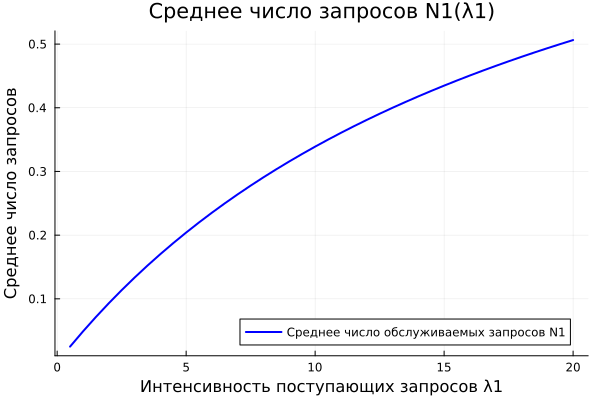

In [15]:
# 7. Построение графиков

#№ 7.1 График зависимости среднего числа обслуживаемых запросов N1 от интенсивности λ1
plot(lambda1_range, N1_range,
     label = "Среднее число обслуживаемых запросов N1",
     xlabel = "Интенсивность поступающих запросов λ1",
     ylabel = "Среднее число запросов",
     title = "Среднее число запросов N1(λ1)",
     linewidth = 2,
     color = :blue,
     legend = :bottomright)

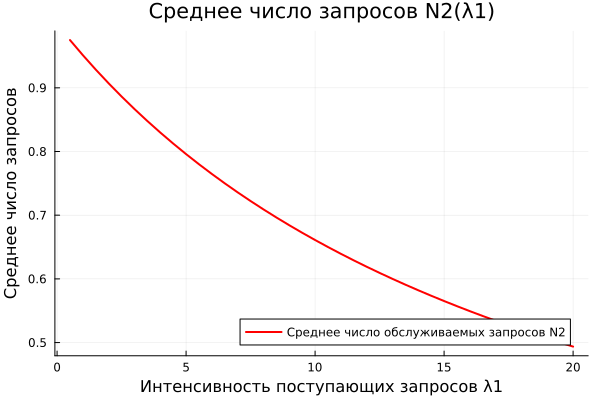

In [16]:
#№ 7.2 График зависимости среднего числа обслуживаемых запросов N2 от интенсивности λ1
plot(lambda1_range, N2_range,
     label = "Среднее число обслуживаемых запросов N2",
     xlabel = "Интенсивность поступающих запросов λ1",
     ylabel = "Среднее число запросов",
     title = "Среднее число запросов N2(λ1)",
     linewidth = 2,
     color = :red,
     legend = :bottomright)

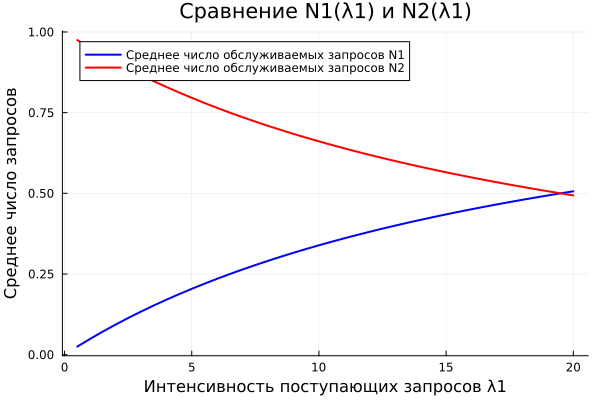

In [17]:
## 7.3 График зависимости среднего числа обслуживаемых запросов N1 и N2 от интенсивности λ1
plot(lambda1_range, N1_range,
     label = "Среднее число обслуживаемых запросов N1",
     xlabel = "Интенсивность поступающих запросов λ1",
     ylabel = "Среднее число запросов",
     title = "Сравнение N1(λ1) и N2(λ1)",
     linewidth = 2,
     color = :blue,
     legend = :topleft)
plot!(lambda1_range, N2_range,
     label = "Среднее число обслуживаемых запросов N2",
     linewidth = 2,
     color = :red)

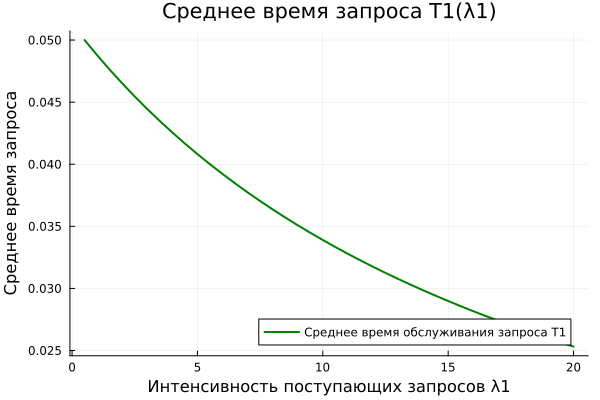

In [18]:
#№ 7.4 График зависимости среднего времени обслуживания запроса T1 от интенсивности λ1
plot(lambda1_range, T1_range,
     label = "Среднее время обслуживания запроса T1",
     xlabel = "Интенсивность поступающих запросов λ1",
     ylabel = "Среднее время запроса",
     title = "Среднее время запроса T1(λ1)",
     linewidth = 2,
     color = :green,
     legend = :bottomright)

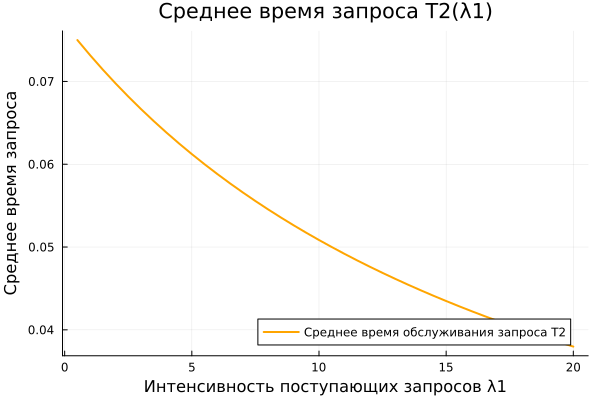

In [19]:
#№ 7.5 График зависимости среднего времени обслуживания запроса T2 от интенсивности λ1
plot(lambda1_range, T2_range,
     label = "Среднее время обслуживания запроса T2",
     xlabel = "Интенсивность поступающих запросов λ1",
     ylabel = "Среднее время запроса",
     title = "Среднее время запроса T2(λ1)",
     linewidth = 2,
     color = :orange,
     legend = :bottomright)

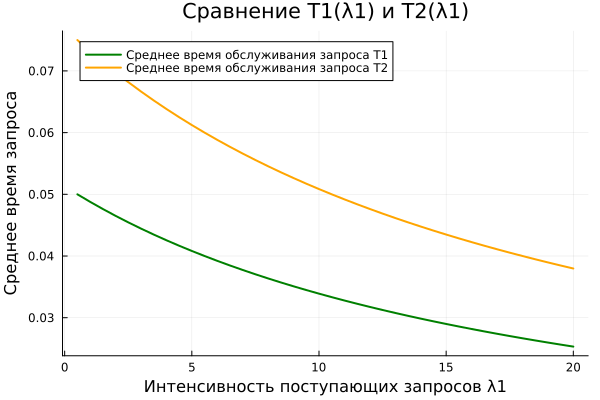

In [20]:
## 7.6 График зависимости среднего времени обслуживания запроса T1 и T2 от интенсивности λ1
plot(lambda1_range, T1_range,
     label = "Среднее время обслуживания запроса T1",
     xlabel = "Интенсивность поступающих запросов λ1",
     ylabel = "Среднее время запроса",
     title = "Сравнение T1(λ1) и T2(λ1)",
     linewidth = 2,
     color = :green,
     legend = :topleft)
plot!(lambda1_range, T2_range,
     label = "Среднее время обслуживания запроса T2",
     linewidth = 2,
     color = :orange)